# Phase 4 — CatBoost

**Follows:** `04_traditional_models.ipynb` (tuned Random Forest: val PR-AUC 0.716).

**Why CatBoost for this data:**
- **Native categorical handling.** `mcc` (109 levels), `use_chip` and card type are encoded with *ordered target statistics*: each row's encoding uses only the rows before it in a random order, so its own label never leaks into its own feature.
- **Gradient boosting.** Each tree corrects the previous trees' errors, and on tabular data with interactions it's usually the strongest model family.
- **Robust defaults.** Symmetric (oblivious) trees are fast to score and less prone to overfitting.

**Protocol:** the same as every model (`src/evaluation.py`). Fit on undersampled training data, score on the full 2018 validation year, threshold chosen on validation. The 2019 test set isn't loaded.

**Lesson from Phase 3:** the Random Forest's best `start_year` (2010) and `neg_per_pos` (40) were at the edge of their search ranges. Here both ranges are wider.

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import average_precision_score

from src.data import PROJECT_ROOT
from src.modeling import (TARGET, load_split, feature_sets, undersample,
                          catboost_frame, categorical_in)
from src.evaluation import evaluate, compare, plot_pr_curves

sns.set_style("whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 0
MODELS_DIR = PROJECT_ROOT / "models"; MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / "reports"
TRAIN_DIR = PROJECT_ROOT / "models" / "catboost_info"     # keep CatBoost's log files out of the repo

FEATURES = feature_sets()["selected"]
CATS = categorical_in(FEATURES)
train = load_split("train", FEATURES + ["year"])
val = load_split("val", FEATURES)
y_val = val[TARGET].to_numpy()
val_pool = Pool(catboost_frame(val, FEATURES), y_val, cat_features=CATS)
print(f"{len(FEATURES)} features ({len(CATS)} categorical) | val {len(val):,} rows, {y_val.sum():,} frauds")

C:\Users\001\.conda\envs\fraud-detection\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


30 features (3 categorical) | val 1,721,615 rows, 2,491 frauds


In [2]:
def training_pool(neg_per_pos, start_year=1991, seed=SEED):
    s = undersample(train[train["year"] >= start_year], neg_per_pos, seed=seed)
    return Pool(catboost_frame(s, FEATURES), s[TARGET], cat_features=CATS), len(s)

def fit_catboost(neg_per_pos=10, start_year=1991, early_stop=True, **params):
    pool, n = training_pool(neg_per_pos, start_year)
    base = dict(iterations=500, depth=6, learning_rate=0.1, random_seed=SEED, verbose=0,
                thread_count=-1, task_type="CPU", train_dir=str(TRAIN_DIR))
    base.update(params)
    if early_stop:
        # Stop when validation PR-AUC hasn't improved for 150 trees; keep the best tree count.
        base.update(eval_metric="PRAUC", od_type="Iter", od_wait=150, metric_period=50)
        model = CatBoostClassifier(**base).fit(pool, eval_set=val_pool, use_best_model=True)
    else:
        model = CatBoostClassifier(**base).fit(pool)
    return model, n

results, val_scores = {}, {}

## 1. Baseline

The same untuned settings as the feature-selection notebook: 500 trees, depth 6, learning rate 0.1, all training years, 1 fraud : 10 non-frauds. No early stopping.

In [3]:
t0 = time.time()
cb_base, n = fit_catboost(early_stop=False)
val_scores["CatBoost (baseline)"] = cb_base.predict_proba(val_pool)[:, 1]
results["CatBoost (baseline)"] = evaluate(y_val, val_scores["CatBoost (baseline)"])
print(f"{n:,} training rows, {time.time() - t0:.0f}s")
compare(results)

276,969 training rows, 40s


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
CatBoost (baseline),0.7322,0.9989,0.7824,0.7805,0.5395,0.8585,0.6858,0.6511,2365.0


### Why CPU and not the GPU?

CatBoost can train on the RTX 3060, but a timing test with identical settings (2010+ data, 1:40 sample, depth 8) gave:

| Device | Fit time | Val PR-AUC |
|---|---|---|
| GPU | 80 s | 0.766 |
| CPU | 243 s | **0.836** |

The GPU is 3× faster but costs **0.07 PR-AUC**. GPU mode uses coarser feature binning and a different, cheaper scheme for combining categorical features. On this data, where `mcc` and merchant interactions carry most of the signal, that difference matters. Accuracy wins, so tuning runs on CPU.

## 2. Tuning with Optuna

💡 **What's searched:**

| Parameter | Range | Why |
|---|---|---|
| `start_year` | 1991 … 2014 | Phase 3 found recent data better for trees. Is 2010 really the best cut-off? |
| `neg_per_pos` | 10 … 100 | Phase 3's best (40) was the top of its range |
| `depth` | 4 – 10 | Interaction order each tree can capture |
| `learning_rate` | 0.02 – 0.2 (log) | Smaller is more careful but needs more trees |
| `l2_leaf_reg` | 1 – 30 (log) | Shrinks leaf values, which fights overfitting to rare frauds |
| `auto_class_weights` | none / SqrtBalanced | Extra up-weighting of fraud on top of the undersampling |
| `random_strength` | 0.5 – 5 | Noise added to split scores, a regularizer |

**Number of trees** isn't searched. Each trial trains up to 3,000 trees and **stops early** when validation PR-AUC hasn't improved for 150 trees.

**Budget:** up to 30 trials or 3 hours, whichever comes first. Large samples (e.g. all years at 1:100 = 2.5M rows) take 10+ minutes per trial on CPU.

In [4]:
def cb_objective(trial):
    params = dict(
        start_year=trial.suggest_categorical("start_year", [1991, 2005, 2008, 2010, 2012, 2014]),
        neg_per_pos=trial.suggest_categorical("neg_per_pos", [10, 20, 40, 70, 100]),
        depth=trial.suggest_int("depth", 4, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        auto_class_weights=trial.suggest_categorical("auto_class_weights", ["None", "SqrtBalanced"]),
        random_strength=trial.suggest_float("random_strength", 0.5, 5),
    )
    model, n = fit_catboost(iterations=3000, **params)
    trial.set_user_attr("best_iteration", model.get_best_iteration())
    trial.set_user_attr("train_rows", n)
    return average_precision_score(y_val, model.predict_proba(val_pool)[:, 1])

t0 = time.time()
cb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
# Seed the search with the two configurations from the timing test
cb_study.enqueue_trial(dict(start_year=2010, neg_per_pos=40, depth=8, learning_rate=0.08,
                            l2_leaf_reg=3, auto_class_weights="None", random_strength=1))
cb_study.enqueue_trial(dict(start_year=1991, neg_per_pos=100, depth=8, learning_rate=0.08,
                            l2_leaf_reg=3, auto_class_weights="None", random_strength=1))
cb_study.optimize(cb_objective, n_trials=30, timeout=3 * 3600)
print(f"{len(cb_study.trials)} trials in {(time.time() - t0) / 60:.0f} min | best val PR-AUC {cb_study.best_value:.4f}")
best = dict(cb_study.best_params)
best["iterations"] = cb_study.best_trial.user_attrs["best_iteration"] + 1
best

11 trials in 181 min | best val PR-AUC 0.8636


{'start_year': 2010,
 'neg_per_pos': 100,
 'depth': 7,
 'learning_rate': 0.051962727109326846,
 'l2_leaf_reg': 2.459125638339734,
 'auto_class_weights': 'None',
 'random_strength': 3.057952769908918,
 'iterations': 759}

In [5]:
cb_trials = cb_study.trials_dataframe()
cols = ["number", "value", "user_attrs_train_rows", "user_attrs_best_iteration"] + \
       [c for c in cb_trials.columns if c.startswith("params_")]
cb_trials[cols].sort_values("value", ascending=False).head(10)

,number,value,user_attrs_train_rows,user_attrs_best_iteration,params_auto_class_weights,params_depth,params_l2_leaf_reg,params_learning_rate,params_neg_per_pos,params_random_strength,params_start_year
3,3,0.863648,1556208,758,None,7,2.459126,0.051963,100,3.057953,2010
10,10,0.859968,2046058,2632,None,9,3.811504,0.020617,100,2.439987,2008
1,1,0.846203,2543079,1032,None,8,3.000000,0.080000,100,1.000000,1991
0,0,0.836141,631728,404,None,8,3.000000,0.080000,40,1.000000,2010
9,9,0.781746,1093968,695,SqrtBalanced,8,1.585301,0.053678,70,3.158927,2010
2,2,0.744788,962926,770,SqrtBalanced,7,23.292627,0.073973,40,0.590983,2005
8,8,0.738545,493206,494,None,6,3.852007,0.130265,20,4.467809,2005
4,4,0.726608,472238,1029,SqrtBalanced,8,1.550386,0.032465,40,3.065885,2012
7,7,0.705910,472238,1211,SqrtBalanced,8,16.766597,0.020948,40,1.715036,2012
5,5,0.684686,493206,1701,SqrtBalanced,8,1.951533,0.027492,20,0.936956,2005


### Which settings mattered?

Optuna's importance estimate (fANOVA): how much of the variation in validation PR-AUC across trials each parameter explains.

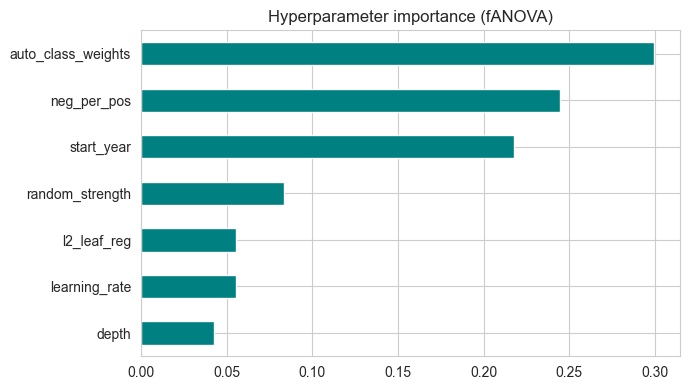

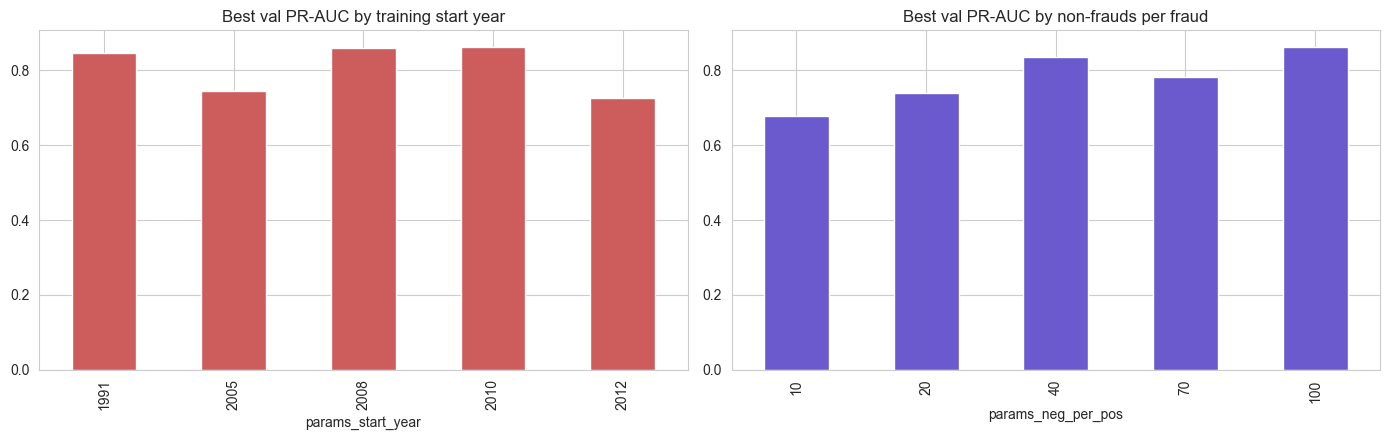

In [6]:
imp = pd.Series(optuna.importance.get_param_importances(cb_study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED)))
imp.sort_values().plot(kind="barh", figsize=(7, 4), color="teal")
plt.title("Hyperparameter importance (fANOVA)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cb_trials.groupby("params_start_year")["value"].max().plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("Best val PR-AUC by training start year")
cb_trials.groupby("params_neg_per_pos")["value"].max().plot(kind="bar", ax=axes[1], color="slateblue")
axes[1].set_title("Best val PR-AUC by non-frauds per fraud")
plt.tight_layout()
plt.show()

### Final tuned model

Refit with the best settings and a **fixed** tree count (the best trial's early-stopping point), so the final model doesn't depend on validation during training.

In [7]:
t0 = time.time()
fit_params = {k: v for k, v in best.items()}
cb_tuned, n = fit_catboost(early_stop=False, **fit_params)
val_scores["CatBoost (tuned)"] = cb_tuned.predict_proba(val_pool)[:, 1]
results["CatBoost (tuned)"] = evaluate(y_val, val_scores["CatBoost (tuned)"])
print(f"{n:,} training rows, {best['iterations']} trees, {time.time() - t0:.0f}s")
compare(results)

1,556,208 training rows, 759 trees, 288s


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
CatBoost (baseline),0.7322,0.9989,0.7824,0.7805,0.5395,0.8585,0.6858,0.6511,2365.0
CatBoost (tuned),0.8636,0.9989,0.9049,0.9338,0.6455,0.4993,0.8198,0.7836,2381.0


## 3. Comparison with the traditional models

C:\Users\001\AppData\Local\Temp\ipykernel_5512\1531346324.py:13: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


C:\Users\001\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


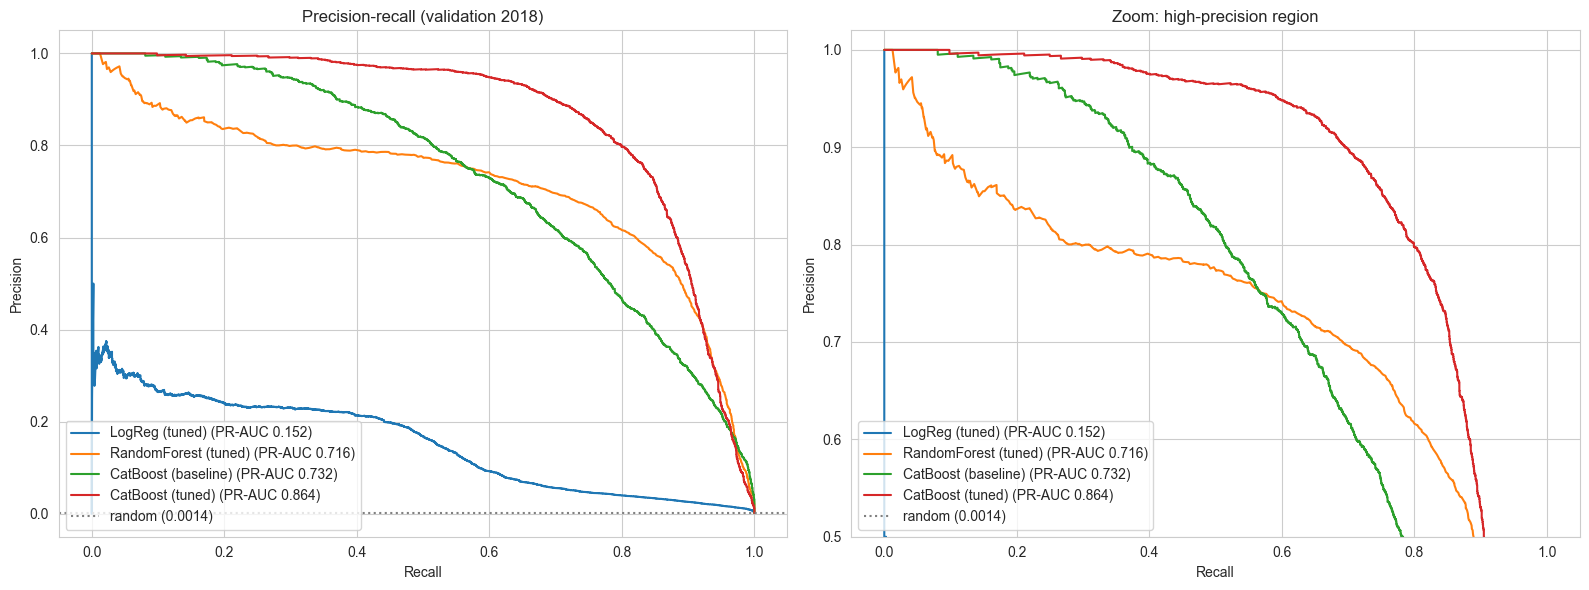

,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (tuned),0.1521,0.9825,0.0024,0.2515,0.1738,0.9787,0.2104,0.4287,5076.0
RandomForest (tuned),0.7155,0.9990,0.8888,0.7648,0.5287,0.5780,0.6653,0.7563,2832.0
CatBoost (baseline),0.7322,0.9989,0.7824,0.7805,0.5395,0.8585,0.6858,0.6511,2365.0
CatBoost (tuned),0.8636,0.9989,0.9049,0.9338,0.6455,0.4993,0.8198,0.7836,2381.0


In [8]:
trad_scores = pd.read_parquet(PROJECT_ROOT / "data" / "cache" / "val_scores_traditional.parquet")
all_scores = {"LogReg (tuned)": trad_scores["LogReg (tuned)"].to_numpy(),
              "RandomForest (tuned)": trad_scores["RandomForest (tuned)"].to_numpy(),
              **val_scores}

all_results = pd.concat([pd.read_csv(REPORTS_DIR / "val_metrics_traditional.csv", index_col=0)
                           .loc[["LogReg (tuned)", "RandomForest (tuned)"]],
                         compare(results)])
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pr_curves(y_val, all_scores, ax=axes[0])
plot_pr_curves(y_val, all_scores, ax=axes[1], title="Zoom: high-precision region")
axes[1].set_ylim(0.5, 1.02)
plt.tight_layout()
plt.show()
all_results

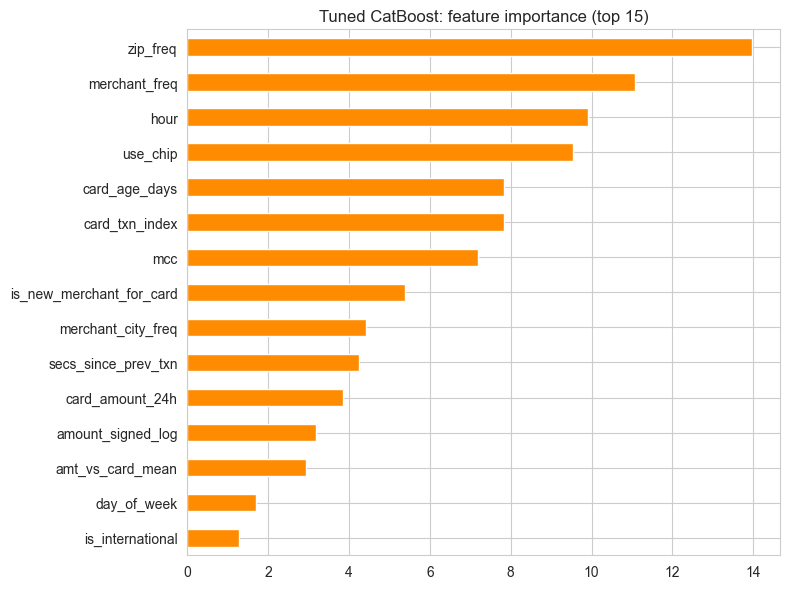

In [9]:
imp = pd.Series(cb_tuned.get_feature_importance(type="PredictionValuesChange"), index=FEATURES).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 6), color="darkorange")
plt.title("Tuned CatBoost: feature importance (top 15)")
plt.tight_layout()
plt.show()

### Findings

**CatBoost is the best model so far.** Tuned CatBoost reaches **val PR-AUC 0.864**, compared with 0.716 for the tuned Random Forest and 0.152 for logistic regression. At the alert threshold chosen on validation, it raises about the same number of alerts as the baseline (2,381 vs 2,365) but is far more accurate: **precision 0.82 and recall 0.78**, against 0.67 / 0.76 for the Random Forest with 2,832 alerts. Among the top 0.1% of scores, 93% are fraud. ROC-AUC is ≈0.999 for all three tree models and does not separate them, which is why PR-AUC is the headline metric.

**Tuning made a large difference: +0.13 PR-AUC over the untuned baseline (0.732 → 0.864).** The search hit its 3-hour limit after **11 of 30 trials**, so it is far from exhaustive. Still, the trials show clear patterns:
- **Keep more non-frauds.** All three best trials used 1 fraud : 100 non-frauds, the largest ratio in the search range. Every trial at 1:20 or below scored under 0.74. Because the best value is at the edge of the range, a larger ratio, or no undersampling at all, may do even better.
- **Don't reweight the classes.** All `SqrtBalanced` trials scored 0.78 or lower; every trial above 0.80 used `None`. Undersampling already rebalances the classes, and extra weighting pushes the probabilities too far toward fraud.
- **Recent data is enough.** Training on 2010+ (1.56M rows) beat training on all years from 1991 (2.54M rows, 0.846) with similar settings. The best model is also faster to train (≈5 min).
- Moderate depth (7–9) and a learning rate around 0.02–0.05 with early stopping worked best. With only 11 trials, the fANOVA importances above are rough estimates.

**Feature importance.** The top features are how common the transaction's zip code and merchant are (`zip_freq`, `merchant_freq`), `hour`, `use_chip`, how old the card is and how many transactions it has made (`card_age_days`, `card_txn_index`), and `mcc`. Velocity features (`is_new_merchant_for_card`, `secs_since_prev_txn`, `card_amount_24h`) come next. This matches what the EDA showed: fraud tends to happen at rare merchants and locations, at unusual hours and in online transactions.

**Caveat: the 0.864 is optimistic.** The validation year was used both for early stopping (which picks the tree count) and for choosing the best trial, so this number has been tuned on validation. The comparison with the Random Forest is still fair, because the Random Forest was also tuned on validation. The unbiased number will come from the single test-set (2019) evaluation in the final phase.

**Possible follow-ups (not run):** a longer or narrower search with `neg_per_pos` ≥ 100 and `start_year` 2008–2012, and averaging across several random seeds to measure how much results vary between runs.

## 4. Save

In [10]:
cb_tuned.save_model(str(MODELS_DIR / "catboost_tuned.cbm"))
compare(results).to_csv(REPORTS_DIR / "val_metrics_catboost.csv")
(REPORTS_DIR / "best_params_catboost.json").write_text(json.dumps(
    {"catboost": {"params": best, "val_threshold": results["CatBoost (tuned)"]["threshold"]}}, indent=2, default=str))
cb_trials[cols].to_csv(REPORTS_DIR / "optuna_trials_catboost.csv", index=False)
pd.DataFrame(val_scores).astype("float32").to_parquet(PROJECT_ROOT / "data" / "cache" / "val_scores_catboost.parquet")
print("Saved model, params, trials and validation metrics.")

Saved model, params, trials and validation metrics.
